# Can a model predict whether SPY goes up tomorrow?

**The question:** using only information available at today's close, can a model predict whether the S&P 500 (through the SPY fund) closes higher tomorrow, better than simple rules can?

**Why direction, not price:** tomorrow's price is almost always close to today's, so a "predicted vs. actual price" chart looks impressive even for a model that has learned nothing. Up-or-down is a much harder test to fake.

**What "honest" means in this notebook:**
1. **No peeking at the future.** Every feature uses only data up to today's close, and the model is always tested on years it never saw during training.
2. **Real baselines.** Beating a coin flip is easy because markets rise slightly more often than they fall. The bar is the rule "always predict up."
3. **Noise check.** Every accuracy comes with a range showing how much could be luck.
4. **Money check.** A backtest with trading costs, compared against simply buying and holding.

In [1]:
import sys
from pathlib import Path

# Let the notebook import the code in ../src
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.data import load_prices, make_random_walk
from src.features import FEATURES, build_dataset
from src.evaluate import (get_models, walk_forward, baseline_predictions,
                          accuracy_table, accuracy_by_year, backtest_table)

pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams["figure.figsize"] = (11, 4)

# Settings: change these to experiment
TICKER = "SPY"
START = "2005-01-01"
FIRST_TEST_YEAR = 2010   # train on 2005-2009 first, then step forward a year at a time
COST = 0.001             # 0.1% cost per buy or sell in the backtest

## 1. Data

Daily prices, adjusted for dividends and splits. The first run downloads them; later runs load the saved copy in `data/`. Use `load_prices(..., refresh=True)` to pull the latest days.

5,477 trading days, 2005-01-03 to 2026-10-09


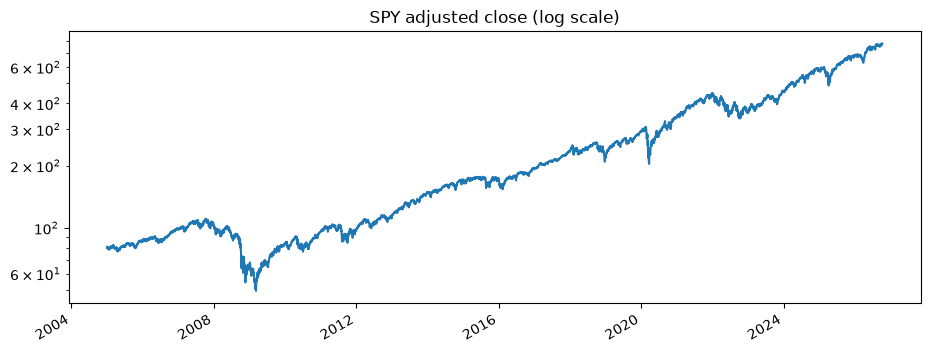

In [2]:
prices = load_prices(TICKER, START)
print(f"{len(prices):,} trading days, {prices.index[0].date()} to {prices.index[-1].date()}")

ax = prices["Close"].plot(logy=True, title=f"{TICKER} adjusted close (log scale)")
ax.set_xlabel("")
plt.show()

In [3]:
daily_ret = prices["Close"].pct_change().dropna()
print(f"Share of up days: {(daily_ret > 0).mean():.1%}")

Share of up days: 55.0%


That share is the accuracy of "always predict up." Any model has to beat it, not 50%, to show it has learned something.

## 2. Features and label

| Feature | Meaning |
|---|---|
| `ret_1d`, `ret_5d`, `ret_10d`, `ret_20d` | Return over the last 1, 5, 10 and 20 days (momentum) |
| `dist_ma10`, `dist_ma50` | How far today's price is above or below its 10- and 50-day average (trend) |
| `vol_20d` | How jumpy daily returns were over the last 20 days (risk) |
| `volume_ratio` | Today's volume compared with its 20-day average (activity) |

The **label** (`target`) is 1 if tomorrow's close is higher than today's, else 0. `next_ret` is tomorrow's return, kept for the backtest.

In [4]:
data = build_dataset(prices)
data.head()

,ret_1d,ret_5d,ret_10d,ret_20d,dist_ma10,dist_ma50,vol_20d,volume_ratio,next_ret,target
Date,,,,,,,,,,
2005-03-15,-0.0083,-0.0179,-0.0090,-0.0045,-0.0105,0.0048,0.0073,0.0720,-0.0085,0
2005-03-16,-0.0085,-0.0153,-0.0169,-0.0166,-0.0172,-0.0035,0.0075,0.2521,0.0020,1
2005-03-17,0.0020,-0.0155,-0.0153,-0.0153,-0.0137,-0.0016,0.0075,0.0404,-0.0030,0
2005-03-18,-0.0030,-0.0115,-0.0303,-0.0102,-0.0136,-0.0047,0.0073,-0.0004,-0.0037,0
2005-03-21,-0.0037,-0.0213,-0.0344,-0.0152,-0.0138,-0.0084,0.0073,0.0051,-0.0102,0


How strongly does each feature relate to tomorrow's return? Correlation runs from -1 to 1. Expect numbers very close to zero, which is the first hint of how hard this is.

In [5]:
data[FEATURES].corrwith(data["next_ret"]).sort_values().to_frame("correlation with next-day return")

,correlation with next-day return
ret_1d,-0.1036
dist_ma10,-0.0859
ret_5d,-0.0767
dist_ma50,-0.0527
ret_10d,-0.0508
ret_20d,-0.0398
volume_ratio,0.0060
vol_20d,0.0071


## 3. Walk-forward testing

A random train/test split would let the model train on 2020 and then "predict" 2015, which is peeking at the future. Instead:

- Train on 2005–2009, predict every day of 2010.
- Train on 2005–2010, predict every day of 2011.
- ...and so on up to today.

Every prediction is made by a model that only saw earlier years, just like it would be used in real life.

In [6]:
model_preds = {}
for name, model in get_models().items():
    model_preds[name] = walk_forward(model, data, FIRST_TEST_YEAR)
    print(f"{name}: done")

test = data[data.index.year >= FIRST_TEST_YEAR]
baselines = baseline_predictions(test)

all_preds = {name: p["pred"] for name, p in model_preds.items()}
all_preds.update({name: baselines[name] for name in baselines})
print(f"Test period: {test.index[0].date()} to {test.index[-1].date()} ({len(test):,} days)")

Logistic regression: done
Gradient boosting: done
Test period: 2010-01-04 to 2026-10-08 (4,217 days)


## 4. Results: accuracy

How to read this table:
- **range low / range high**: the 95% range. Two methods whose ranges overlap heavily can't really be told apart.
- **predicted up**: if a model says "up" on nearly every day, it has mostly learned "always up," not a real pattern.
- **p-value vs coin flip**: small values mean it beats coin flipping. Notice "Always up" passes this test too, which is why it's a weak test.
- **beats always-up?**: the honest test. True only if the model is better than "always up" by more than noise.

In [7]:
accuracy_table(all_preds, test["target"])

,accuracy,range low,range high,predicted up,p-value vs coin flip,beats always-up?
Logistic regression,0.5509,0.5359,0.5659,0.9758,0.0000,False
Gradient boosting,0.5269,0.5118,0.5420,0.7697,0.0002,False
Coin flip,0.4925,0.4774,0.5076,0.5039,0.8378,False
Always up,0.5523,0.5373,0.5673,1.0000,0.0000,False
Repeat last move,0.4973,0.4822,0.5124,0.5523,0.6442,False


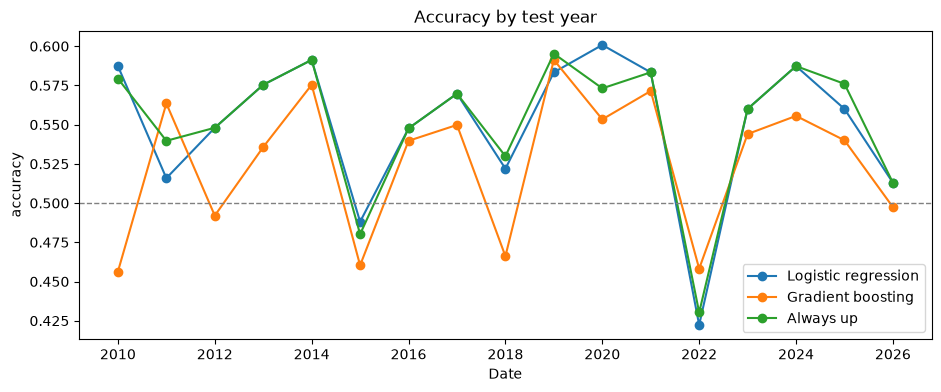

In [8]:
by_year = accuracy_by_year(all_preds, test["target"])
ax = by_year[list(model_preds) + ["Always up"]].plot(marker="o", title="Accuracy by test year")
ax.axhline(0.5, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("accuracy")
plt.show()

Questions to ask yourself here: does a model beat "always up" consistently, or only in a few years? Which years are bad, and what happened in markets then?

## 5. Backtest: would it have made money?

Strategy: at each close, hold SPY into tomorrow if the model predicts up, otherwise sit in cash. Each buy or sell costs `COST`. Compared against buying once and holding.

In [9]:
positions = {"Buy and hold": pd.Series(1, index=test.index)}
positions.update({name: p["pred"] for name, p in model_preds.items()})

stats, daily_returns = backtest_table(positions, test["next_ret"], cost=COST)
stats

,total return,annual return,annual volatility,Sharpe ratio,max drawdown,days in market,trades
Buy and hold,8.2229,0.1420,0.1704,0.8648,-0.3372,1.0000,1
Logistic regression,7.1262,0.1334,0.1625,0.8519,-0.2885,0.9758,151
Gradient boosting,0.9623,0.0411,0.1449,0.3506,-0.3086,0.7697,1053


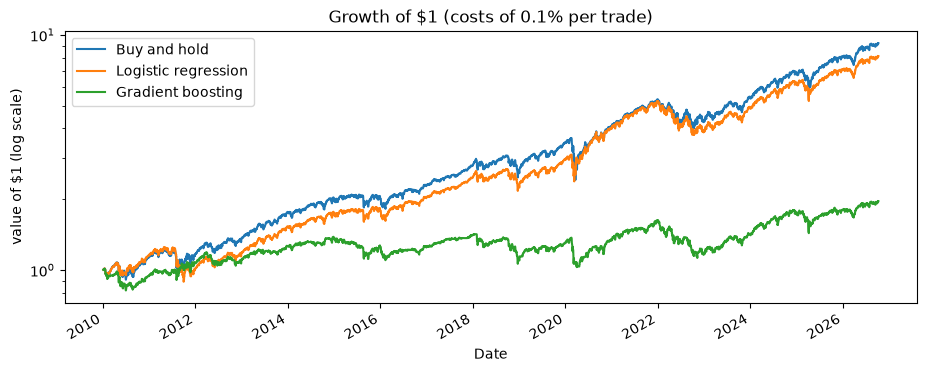

In [10]:
ax = (1 + daily_returns).cumprod().plot(logy=True, title=f"Growth of $1 (costs of {COST:.1%} per trade)")
ax.set_ylabel("value of $1 (log scale)")
plt.show()

Trading costs matter. Here's the same backtest at different cost levels. A strategy that only wins when trading is free isn't a real edge.

In [11]:
rows = {}
for cost in [0, 0.0005, 0.001, 0.002]:
    s, _ = backtest_table(positions, test["next_ret"], cost=cost)
    rows[f"{cost:.2%}"] = s["annual return"]
pd.DataFrame(rows).rename_axis(columns="cost per trade")

cost per trade,0.00%,0.05%,0.10%,0.20%
Buy and hold,0.1420,0.1420,0.1420,0.1419
Logistic regression,0.1436,0.1385,0.1334,0.1232
Gradient boosting,0.1087,0.0744,0.0411,-0.0225


## 6. Sanity check: a random walk

Run the exact same pipeline on fake prices where every day is pure chance. Nothing can be predicted, so the models should land close to "always up." If a model clearly beats it here, the code is leaking future information and the real results can't be trusted.

In [12]:
fake = build_dataset(make_random_walk(n_days=len(prices), start=prices.index[0]))
fake_test = fake[fake.index.year >= FIRST_TEST_YEAR]

fake_preds = {name: walk_forward(m, fake, FIRST_TEST_YEAR)["pred"] for name, m in get_models().items()}
fake_preds["Always up"] = pd.Series(1, index=fake_test.index)
accuracy_table(fake_preds, fake_test["target"])

,accuracy,range low,range high,predicted up,p-value vs coin flip,beats always-up?
Logistic regression,0.4930,0.4779,0.5082,0.3895,0.8195,False
Gradient boosting,0.4964,0.4812,0.5116,0.4523,0.6844,False
Always up,0.5029,0.4877,0.5180,1.0000,0.3609,False


## 7. What did logistic regression learn?

Weights from a model fitted on all the data. Features were scaled first, so the sizes are comparable: positive means "this pushes toward predicting up." This describes the model; it doesn't prove the patterns are real.

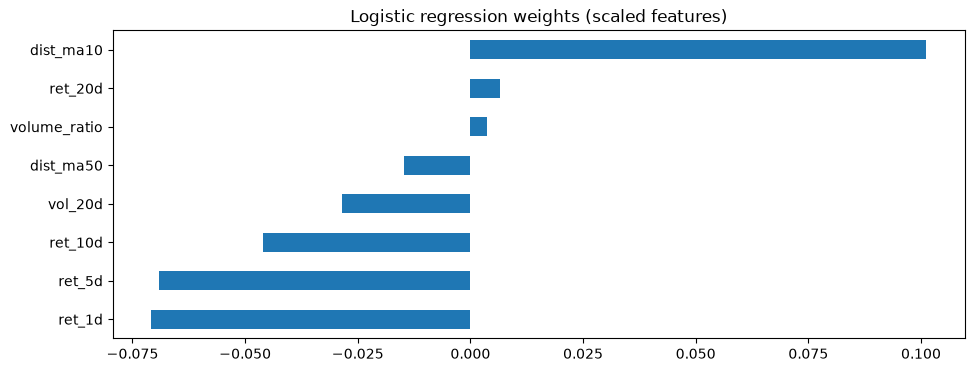

In [13]:
logreg = get_models()["Logistic regression"].fit(data[FEATURES], data["target"])
weights = pd.Series(logreg[-1].coef_[0], index=FEATURES).sort_values()
weights.plot.barh(title="Logistic regression weights (scaled features)")
plt.show()

## 8. Conclusions

*Write this after running the notebook, in your own words. It's the most important part for a portfolio reader.* Some prompts:

- Did either model beat "always up" beyond the noise range? By how much?
- Was any edge consistent across years, or concentrated in a few?
- Did the backtest beat buy-and-hold after costs? On return, on Sharpe ratio, on drawdown?
- What did the random-walk check show?
- Why do you think daily direction is so hard to predict?

## Ideas to try next

- Other tickers (single stocks, other markets, `^VIX`-based features)
- Trade only when the model is confident, e.g. `prob_up > 0.55`
- Predict weekly instead of daily direction
- An LSTM, judged against the same baselines and the same walk-forward test